In [169]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn import linear_model, metrics, model_selection, preprocessing
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
%matplotlib inline

In [170]:
df = pd.read_csv('Salary_Data.csv')
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6690 entries, 0 to 6689
Data columns (total 6 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Age                  6688 non-null   float64
 1   Gender               6688 non-null   str    
 2   Education Level      6687 non-null   str    
 3   Job Title            6688 non-null   str    
 4   Years of Experience  6687 non-null   float64
 5   Salary               6685 non-null   float64
dtypes: float64(3), str(3)
memory usage: 313.7 KB


In [171]:
df.isnull().sum()
#לא חסר הרבה ולכן אסיר את הערכים החסרים

Age                    2
Gender                 2
Education Level        3
Job Title              2
Years of Experience    3
Salary                 5
dtype: int64

In [172]:
df = df.dropna().reset_index(drop=True)
df.isnull().sum()

Age                    0
Gender                 0
Education Level        0
Job Title              0
Years of Experience    0
Salary                 0
dtype: int64

In [173]:
df.describe()

,Age,Years of Experience,Salary
count,6684.000000,6684.000000,6684.000000
mean,33.610563,8.077723,115307.175194
std,7.595994,6.029305,52806.810881
min,21.000000,0.000000,350.000000
25%,28.000000,3.000000,70000.000000
50%,32.000000,7.000000,115000.000000
75%,38.000000,12.000000,160000.000000
max,62.000000,34.000000,250000.000000


In [174]:
df.describe(include='all')

,Age,Gender,Education Level,Job Title,Years of Experience,Salary
count,6684.000000,6684,6684,6684,6684.000000,6684.000000
unique,NaN,2,7,191,NaN,NaN
top,NaN,Male,Bachelor's Degree,Software Engineer,NaN,NaN
freq,NaN,3671,2265,518,NaN,NaN
mean,33.610563,NaN,NaN,NaN,8.077723,115307.175194
std,7.595994,NaN,NaN,NaN,6.029305,52806.810881
min,21.000000,NaN,NaN,NaN,0.000000,350.000000
25%,28.000000,NaN,NaN,NaN,3.000000,70000.000000
50%,32.000000,NaN,NaN,NaN,7.000000,115000.000000
75%,38.000000,NaN,NaN,NaN,12.000000,160000.000000


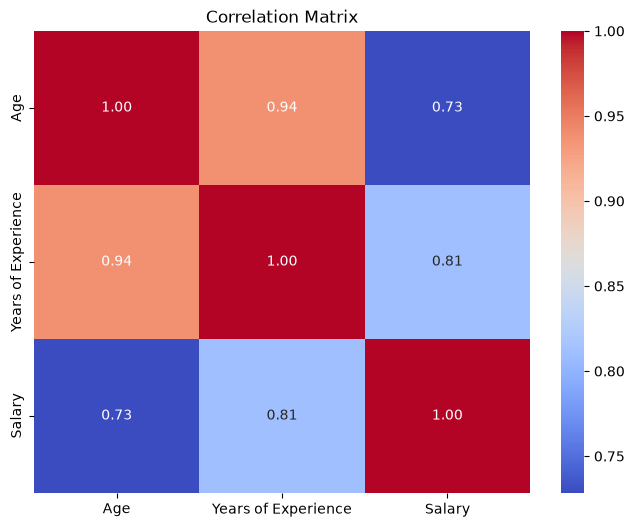

In [175]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title('Correlation Matrix')
plt.show()

In [176]:
df['Job Title'].unique()
#לא נשתמש בJob Title כי יש מדי הרבה סוגים

<StringArray>
[           'Software Engineer',                 'Data Analyst',
               'Senior Manager',              'Sales Associate',
                     'Director',            'Marketing Analyst',
              'Product Manager',                'Sales Manager',
        'Marketing Coordinator',             'Senior Scientist',
 ...
  'Human Resources Coordinator',       'Junior Sales Associate',
      'Human Resources Manager',        'Juniour HR Generalist',
       'Juniour HR Coordinator', 'Digital Marketing Specialist',
                 'Receptionist',           'Marketing Director',
             'Social Media Man',              'Delivery Driver']
Length: 191, dtype: str

In [177]:
df['Education Level'].unique()
# נשתמש כי יש 7 נהפוך לערכים מספריים

<StringArray>
[       'Bachelor's',          'Master's',               'PhD',
 'Bachelor's Degree',   'Master's Degree',       'High School',
               'phD']
Length: 7, dtype: str

In [178]:
df['Education Level'] = df['Education Level'].str.strip().str.lower()
education_mapping = {
    'high school': 1,
    "bachelor's": 2,
    "bachelor's degree": 2,
    "master's": 3,
    "master's degree": 3,
    'phd': 4
}
df['EducationLevel_Num'] = df['Education Level'].map(education_mapping)
df['Gender_NUM'] = df['Gender'].astype('category').cat.codes + 1

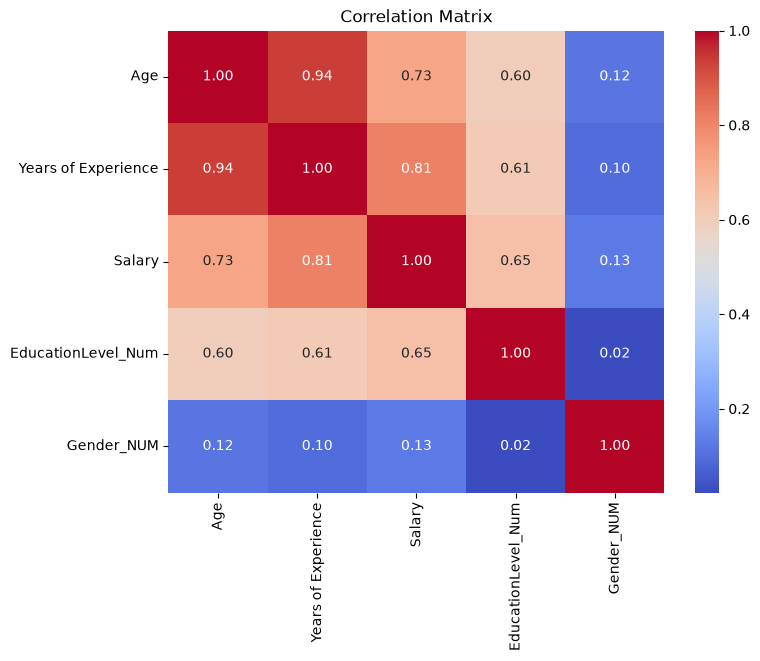

In [179]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.corr(numeric_only=True),
            annot=True,
            cmap='coolwarm',
            fmt='.2f')

plt.title('Correlation Matrix')
plt.show()
#קשרים חזקים מול Age ,Years of Experience ,Education Level

In [181]:
#רגרסיה לינארית ע"פ Years of Experience

X_train0, X_test0, y_train0, y_test0 = train_test_split(df[['Years of Experience']], df['Salary'], test_size=0.2, random_state=42)

lin_model = linear_model.LinearRegression()
lin_model.fit(X_train0, y_train0)
y_pred0 = lin_model.predict(X_test0)

print("R^2: {:.4f}".format(lin_model.score(X_test0, y_test0)))

rmse = np.sqrt(mean_squared_error(y_test0, y_pred0))
print("RMSE: {:.2f}".format(rmse))

R^2: 0.6570
RMSE: 30873.59


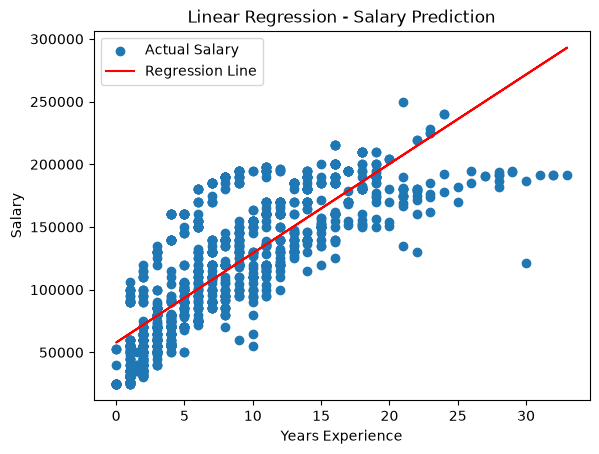

In [ ]:

y_pred = lin_model.predict(X_test0)

plt.scatter(X_test0, y_test0, label='Actual Salary')
plt.plot(X_test0, y_pred, color='red', label='Regression Line')

plt.xlabel('Years Experience')
plt.ylabel('Salary')
plt.title('Linear Regression - Salary Prediction')
plt.legend()
plt.show()

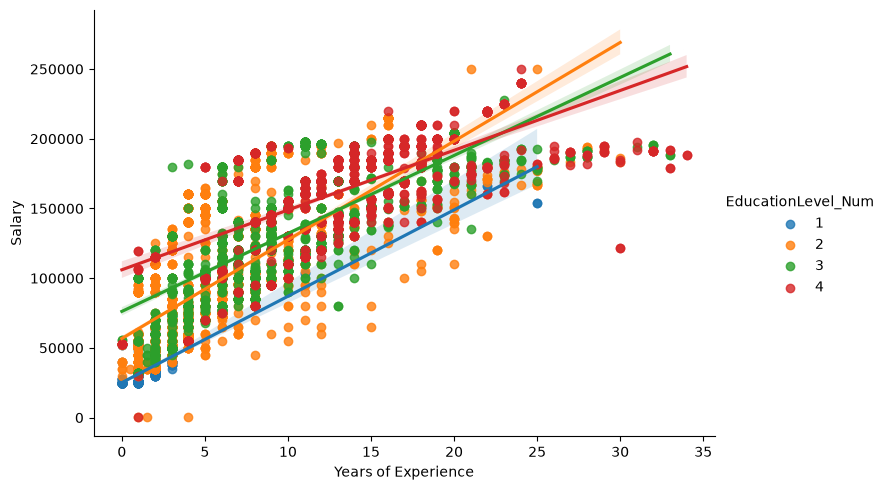

In [ ]:
sns.set_style()
sns.lmplot(data=df, x='Years of Experience', y='Salary', hue='EducationLevel_Num', height=5, aspect=1.5)

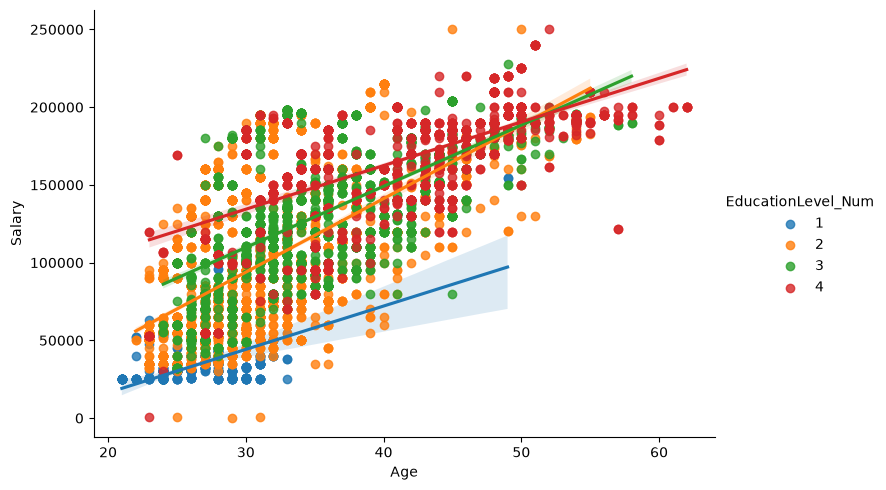

In [ ]:
sns.set_style()
sns.lmplot(data=df, x='Age', y='Salary', hue='EducationLevel_Num', height=5, aspect=1.5)

In [ ]:
numerical_columns = ['EducationLevel_Num', 'Age', 'Years of Experience']
target = df['Salary']
X_train1, X_test1, y_train1, y_test1 = train_test_split(df[numerical_columns].values, target, test_size=0.20, random_state=42)

lin_model_multiple.fit(X_train1, y_train1)
y_pred1 = lin_model_multiple.predict(X_test1)

print("R^2: {:.4f}".format(lin_model_multiple.score(X_test1, y_test1)))

rmse = np.sqrt(mean_squared_error(y_test1, y_pred1))

print("RMSE: {:.2f}".format(rmse))

weights_df = pd.DataFrame({
    'Feature': numerical_columns,
    'W': lin_model_multiple.coef_
})

display(weights_df)

R^2: 0.7035
RMSE: 28703.10


,Feature,W
0,EducationLevel_Num,14914.797408
1,Age,-2111.704187
2,Years of Experience,8292.136665


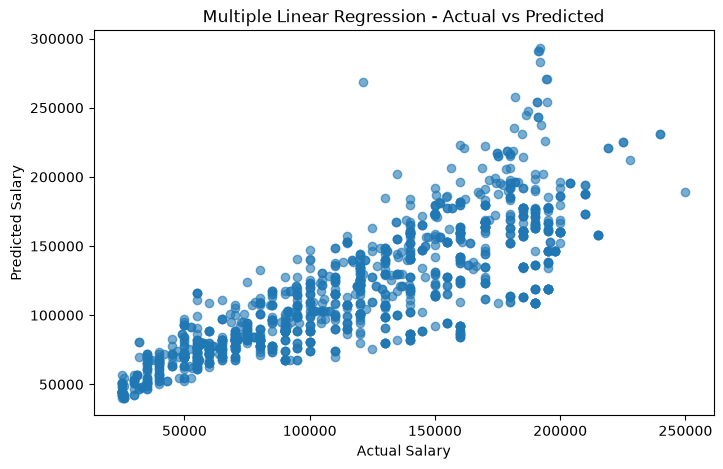

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_test1, y_pred1, alpha=0.6)

plt.xlabel('Actual Salary')
plt.ylabel('Predicted Salary')
plt.title('Multiple Linear Regression - Actual vs Predicted')

plt.show()

In [ ]:
poly = PolynomialFeatures(degree=2)

X = df[['Years of Experience']]
y = df['Salary']

X_poly = poly.fit_transform(X)
X_train2, X_test2, y_train2, y_test2 = train_test_split(X_poly, y, test_size=0.2, random_state=42)

poly_model = linear_model.LinearRegression()

poly_model.fit(X_train2, y_train2)

y_pred2 = poly_model.predict(X_test2)

r2 = r2_score(y_test2, y_pred2)
rmse = np.sqrt(mean_squared_error(y_test2, y_pred2))

print("R^2: {:.4f}".format(r2))
print("RMSE: {:.2f}".format(rmse))

R^2: 0.7365
RMSE: 27059.70


c:\Users\tobyb\AppData\Local\Programs\Python\Python314\Lib\site-packages\sklearn\utils\validation.py:2830: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


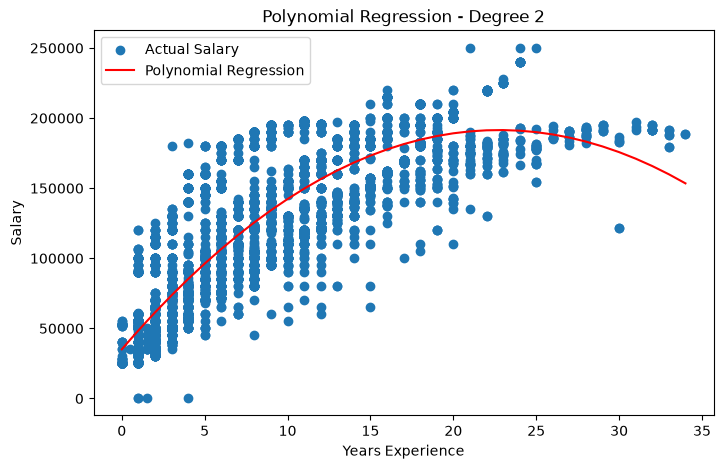

In [ ]:
X_plot = np.sort(X.values, axis=0)
X_plot_poly = poly.transform(X_plot)
y_plot = poly_model.predict(X_plot_poly)

plt.figure(figsize=(8, 5))

plt.scatter(X, y, label='Actual Salary')
plt.plot(X_plot, y_plot, color='red', label='Polynomial Regression')

plt.xlabel('Years Experience')
plt.ylabel('Salary')
plt.title('Polynomial Regression - Degree 2')
plt.legend()
plt.show()

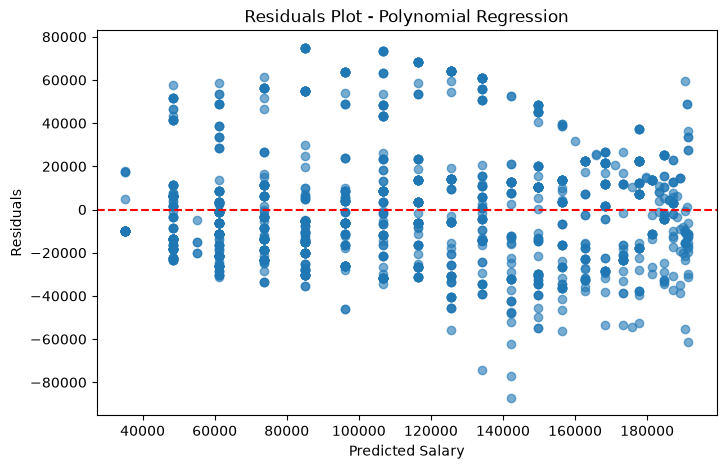

In [ ]:
residuals = y_test2 - y_pred2

plt.figure(figsize=(8, 5))

plt.scatter(y_pred2, residuals, alpha=0.6)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel('Predicted Salary')
plt.ylabel('Residuals')
plt.title('Residuals Plot - Polynomial Regression')

plt.show()

#אין קשר בין השגיאות

שאלות סיכום:

1. 

מודל 1: 
R^2: 0.6570
RMSE: 30873.59

מודל 2:
R^2: 0.7035
RMSE: 28703.10

מודל 3:
R^2: 0.7365
RMSE: 27059.70

מודל 3 הכי טוב R^2 הכי גבוה וRMSE הכי נמוך

לדעתנו זה קרה בגלל שאמנם שנות הניסיון זה המשתנה הכי משמעותי אבל יש התמתנות אם יש הרבה מאד ניסיון

2. כן

3. מתמתן